In [4]:
from __future__ import annotations

import sys
from pathlib import Path

# Make repo root importable so `methods` and `data._utils` both resolve.
# `__file__` is not defined in notebooks, so fall back to the current working dir.
try:
    _THIS = Path(__file__).resolve()
except NameError:
    _THIS = (Path.cwd() / "load_and_investigate_data.ipynb").resolve()

sys.path.insert(0, str(_THIS.parents[1]))
sys.path.insert(0, str(_THIS.parent))

import numpy as np

from _utils import banner, save_dataset

In [5]:
LABEL_NAMES = np.array(["animate_face", "animate_body", "inanimate_natural", "inanimate_artificial"])
N_COND = 92
LABEL_NAMES

array(['animate_face', 'animate_body', 'inanimate_natural',
       'inanimate_artificial'], dtype='<U20')

In [6]:
def _try_rsatoolbox() -> np.ndarray | None:
    """Return the real 92-condition IT RDM if rsatoolbox happens to ship it."""
    try:
        import rsatoolbox                             # noqa: F401
    except Exception:
        return None
    try:
        # Different rsatoolbox versions have shipped this dataset under
        # different names; we probe a few.
        from rsatoolbox.data import load_92           # type: ignore
        ds = load_92()
        # ds.get_measurements() -> (n_channels, n_conditions) in some versions
        # We just want the group-averaged IT RDM.
        from rsatoolbox.rdm import calc_rdm
        rdms = calc_rdm(ds, method="correlation")
        return rdms.get_matrices()[0]
    except Exception:
        pass
    return None

In [7]:
def _try_kriegeskorte_mat(path: str | Path | None = None) -> np.ndarray | None:
    """Load the real Kriegeskorte 2008 human-IT RDM from ``92_brainRDMs.mat``.

    The file (from the RSA-toolbox ``92imageData`` bundle) contains 4 subjects
    x 2 sessions = 8 individual 92x92 RDMs stored as a MATLAB struct array
    with fields ``RDM``, ``name``, ``color``. We return the group-average RDM.
    """
    if path is None:
        path = _THIS.parent / "92_brainRDMs.mat"
    path = Path(path)
    if not path.exists():
        return None
    try:
        from scipy.io import loadmat
        mat = loadmat(str(path), squeeze_me=True, struct_as_record=False)
        rdms = np.asarray(mat["RDMs"]).ravel()     # 8 struct entries
        stacked = np.stack([entry.RDM for entry in rdms], axis=0)   # (8,92,92)
        assert stacked.shape[1:] == (N_COND, N_COND), stacked.shape
        return stacked.mean(axis=0).astype(np.float32)
    except Exception as exc:
        banner(f"failed to load {path.name}: {exc}")
        return None


In [8]:
def _synthesise(rng: np.random.Generator, n_voxels: int = 500, n_runs: int = 6,
                noise_scale: float = 1.2) -> dict:
    """Synthesise 92 conditions with 4 hidden super-categories."""
    # 4 super-categories, roughly 23 exemplars each
    n_per_cat = [23, 23, 23, 23]
    labels = np.concatenate([[c] * n_per_cat[c] for c in range(4)])
    assert len(labels) == N_COND

    # Category-level prototypes in a low-dim latent space
    latent_dim = 8
    proto = rng.standard_normal((4, latent_dim)) * 2.0
    # Exemplar-level variation
    latent = np.zeros((N_COND, latent_dim))
    for i in range(N_COND):
        latent[i] = proto[labels[i]] + 0.7 * rng.standard_normal(latent_dim)

    # Random projection to voxel space
    W = rng.standard_normal((latent_dim, n_voxels)) / np.sqrt(latent_dim)
    true_patterns = latent @ W                        # (92, n_voxels)

    # multi-run noisy measurements
    patterns = (
        true_patterns[None] + noise_scale * rng.standard_normal(
            (n_runs, N_COND, n_voxels)
        )
    )

    # "IT" RDM: 1 - Pearson of clean patterns (this is what a hypothetical
    # noise-free brain would produce). In the real dataset this is the human
    # IT fMRI RDM from Kriegeskorte 2008.
    from methods.classic_rsa import rdm

    it_rdm = rdm(true_patterns, metric="correlation")

    return dict(
        patterns=patterns.astype(np.float32),
        labels=labels.astype(np.int64),
        label_names=LABEL_NAMES,
        it_rdm=it_rdm.astype(np.float32),
        source=np.array("synthesised (4 super-categories, 6 runs, 500 voxels)"),
    )

In [9]:
rng = np.random.default_rng(0)

# Preference order: real .mat file -> rsatoolbox bundle -> synthesised
real_rdm = _try_kriegeskorte_mat()
real_src = "Kriegeskorte 2008 hIT RDM (group avg of 4 subjects x 2 sessions)"
if real_rdm is None:
    real_rdm = _try_rsatoolbox()
    real_src = "rsatoolbox bundled IT RDM"

data = _synthesise(rng)
if real_rdm is not None and real_rdm.shape == (N_COND, N_COND):
    banner(f"using {real_src}")
    data["it_rdm"] = real_rdm.astype(np.float32)
    data["source"] = np.array(f"{real_src} + synthesised runs for crossnobis")
else:
    banner("no real RDM found; synthesising IT RDM as well")
    banner(f"    -> 92 conditions, {data['patterns'].shape[0]} runs, "
           f"{data['patterns'].shape[2]} voxels")
    banner(f"    -> structure: {len(LABEL_NAMES)} super-categories")

p = save_dataset("kriegeskorte92", **data)
banner(f"wrote {p}")


[data] using Kriegeskorte 2008 hIT RDM (group avg of 4 subjects x 2 sessions)
[data] wrote C:\Users\srishtysuman\OfflineRepo\NS_Implem\data\cache\kriegeskorte92.npz


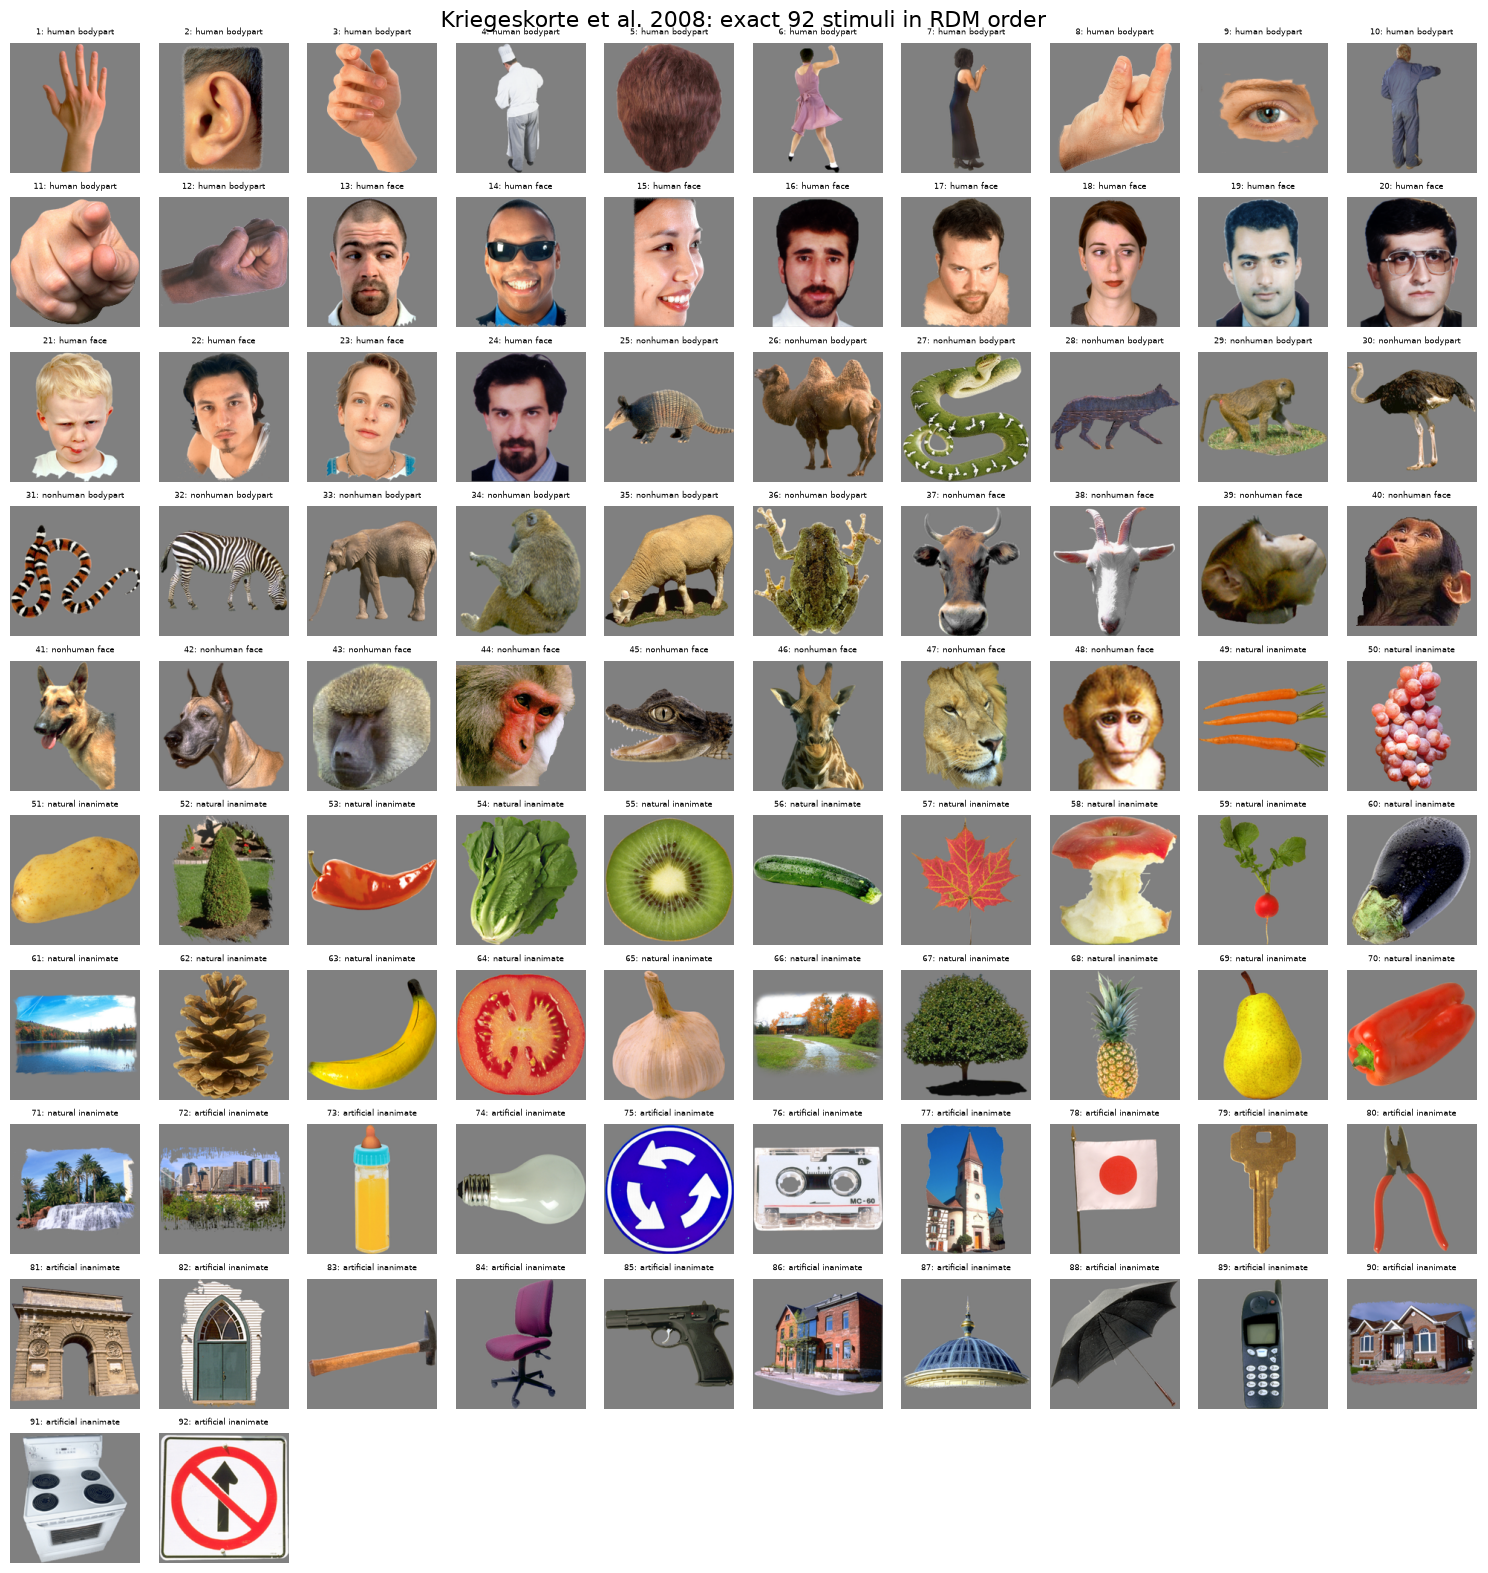

In [10]:
# Exact Kriegeskorte et al. 2008 stimulus images
from scipy.io import loadmat
import matplotlib.pyplot as plt

supplemental_files = list((_THIS.parent / "downloads" / "rsatoolbox-1").rglob(
    "Kriegeskorte_Neuron2008_supplementalData.mat"
))
if len(supplemental_files) != 1:
    raise FileNotFoundError(
        "Expected one official Kriegeskorte supplemental-data file under "
        "data/downloads/rsatoolbox-1/"
    )

supplemental = loadmat(
    supplemental_files[0], squeeze_me=True, struct_as_record=False
)
stimuli = np.asarray(supplemental["stimuli_92objs"]).ravel()
assert len(stimuli) == N_COND
assert all(stimulus.image.shape == (175, 175, 3) for stimulus in stimuli)

fig, axes = plt.subplots(10, 10, figsize=(15, 16))
for index, axis in enumerate(axes.ravel()):
    axis.axis("off")
    if index < len(stimuli):
        stimulus = stimuli[index]
        axis.imshow(stimulus.image)
        axis.set_title(f"{index + 1}: {stimulus.category}", fontsize=6)
fig.suptitle("Kriegeskorte et al. 2008: exact 92 stimuli in RDM order", fontsize=16)
fig.tight_layout()
plt.show()

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
from brainscore_language import load_dataset

output = Path("data/downloads/pereira2018")
output.mkdir(parents=True, exist_ok=True)

data = load_dataset("Pereira2018.language")
multiindex_dims = [
    dim for dim, index in data.indexes.items()
    if isinstance(index, pd.MultiIndex)
]
serializable_data = data.reset_index(multiindex_dims)
for coord_name, coord in serializable_data.coords.items():
    if coord.dtype == object:
        serializable_data = serializable_data.assign_coords(
            {coord_name: (coord.dims, np.asarray(coord.values, dtype=str))}
        )
output_path = output / "Pereira2018_language.nc"
serializable_data.to_netcdf(output_path)

with xr.open_dataarray(output_path) as saved_data:
    assert saved_data.shape == data.shape
    print(f"Saved {output_path} with shape {saved_data.shape}")

Saved data\downloads\pereira2018\Pereira2018_language.nc with shape (627, 13553)


In [12]:
import site, sys
print(sys.executable)
print(site.getsitepackages())

c:\Users\srishtysuman\AppData\Local\anaconda3\envs\ns-implem\python.exe
['c:\\Users\\srishtysuman\\AppData\\Local\\anaconda3\\envs\\ns-implem', 'c:\\Users\\srishtysuman\\AppData\\Local\\anaconda3\\envs\\ns-implem\\Lib\\site-packages']
